In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

Matplotlib is building the font cache; this may take a moment.


In [8]:
df = pd.read_csv("../data/diabetic_data.csv")

In [9]:
df.shape

(101766, 50)


## Dataset Information

- Total records: 101,766
- Total columns: 50
- Each row represents one hospital encounter.
- The dataset contains patient details, hospital visits, diagnoses, medications, and readmission information.

## Column Descriptions

### 1. Patient Information
- encounter_id - Unique ID for each hospital encounter
- patient_nbr - Unique ID for each patient
- race - Race of the patient
- gender - Gender of the patient
- age - Age group of the patient
- weight - Weight range of the patient

### 2. Hospital Admission Information
- admission_type_id - Type of hospital admission
- discharge_disposition_id - Discharge status or destination
- admission_source_id - Source of admission
- time_in_hospital - Number of days spent in hospital
- payer_code - Insurance or payment information
- medical_specialty - Specialty of the treating doctor

### 3. Hospital Visits and Procedures
- num_lab_procedures - Number of lab tests
- num_procedures - Number of other procedures
- num_medications - Number of different medications
- number_outpatient - Outpatient visits in the previous year
- number_emergency - Emergency visits in the previous year
- number_inpatient - Inpatient visits in the previous year

### 4. Diagnosis Information
- diag_1 - Primary diagnosis
- diag_2 - Secondary diagnosis
- diag_3 - Third diagnosis
- number_diagnoses - Total number of diagnoses

### 5. Blood Test Results
- max_glu_serum - Glucose serum test result
- A1Cresult - HbA1c test result

### 6. Diabetes Medications
These columns show the status of different diabetes medications.

- metformin - Metformin
- repaglinide - Repaglinide
- nateglinide - Nateglinide
- chlorpropamide - Chlorpropamide
- glimepiride - Glimepiride
- acetohexamide - Acetohexamide
- glipizide - Glipizide
- glyburide - Glyburide
- tolbutamide - Tolbutamide
- pioglitazone - Pioglitazone
- rosiglitazone - Rosiglitazone
- acarbose - Acarbose
- miglitol - Miglitol
- troglitazone - Troglitazone
- tolazamide - Tolazamide
- examide - Examide
- citoglipton - Citoglipton
- insulin - Insulin
- glyburide-metformin - Combination medication
- glipizide-metformin - Combination medication
- glimepiride-pioglitazone - Combination medication
- metformin-rosiglitazone - Combination medication
- metformin-pioglitazone - Combination medication

Medication values:
- No - Medication not prescribed
- Steady - No change in dosage
- Up - Dosage increased
- Down - Dosage decreased

### 7. Other Medication Information
- change - Whether diabetes medication was changed
- diabetesMed - Whether diabetes medication was prescribed

### 8. Target Column
- readmitted - Shows whether the patient was readmitted

Original values:
- `<30` - Readmitted within 30 days
- `>30` - Readmitted after 30 days
- `NO` - No recorded readmission



In [10]:
df.head()

,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,...,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
0,2278392,8222157,Caucasian,Female,[0-10),?,6,25,1,1,...,No,No,No,No,No,No,No,No,No,NO
1,149190,55629189,Caucasian,Female,[10-20),?,1,1,7,3,...,No,Up,No,No,No,No,No,Ch,Yes,>30
2,64410,86047875,AfricanAmerican,Female,[20-30),?,1,1,7,2,...,No,No,No,No,No,No,No,No,Yes,NO
3,500364,82442376,Caucasian,Male,[30-40),?,1,1,7,2,...,No,Up,No,No,No,No,No,Ch,Yes,NO
4,16680,42519267,Caucasian,Male,[40-50),?,1,1,7,1,...,No,Steady,No,No,No,No,No,Ch,Yes,NO


In [11]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 101766 entries, 0 to 101765
Data columns (total 50 columns):
 #   Column                    Non-Null Count   Dtype
---  ------                    --------------   -----
 0   encounter_id              101766 non-null  int64
 1   patient_nbr               101766 non-null  int64
 2   race                      101766 non-null  str  
 3   gender                    101766 non-null  str  
 4   age                       101766 non-null  str  
 5   weight                    101766 non-null  str  
 6   admission_type_id         101766 non-null  int64
 7   discharge_disposition_id  101766 non-null  int64
 8   admission_source_id       101766 non-null  int64
 9   time_in_hospital          101766 non-null  int64
 10  payer_code                101766 non-null  str  
 11  medical_specialty         101766 non-null  str  
 12  num_lab_procedures        101766 non-null  int64
 13  num_procedures            101766 non-null  int64
 14  num_medications           10176

### 13 numerical columns, and 37 object columns

## checking missing values

In [12]:
missing_values = df.isnull().sum()
percentage = (missing_values/len(df))*100

missing_data = pd.DataFrame({'missing':missing_values, 'Percentage': percentage})
missing_data[missing_data ['missing']>0 ]

,missing,Percentage
max_glu_serum,96420,94.746772
A1Cresult,84748,83.277322


In [13]:
for col in df.columns:
    count = (df[col] =='?').sum()
    
    if count>0:
        print(col, count)

race 2273
weight 98569
payer_code 40256
medical_specialty 49949
diag_1 21
diag_2 358
diag_3 1423


In [14]:
df['readmitted'].value_counts()

readmitted
NO     54864
>30    35545
<30    11357
Name: count, dtype: int64

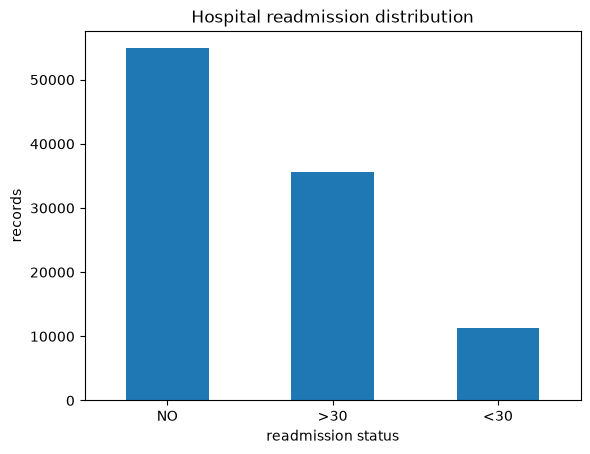

In [15]:
#visualization of the target variable
readmission_count = df['readmitted'].value_counts()
readmission_count.plot(kind='bar')
plt.title('Hospital readmission distribution')
plt.xlabel('readmission status')
plt.ylabel('records')
plt.xticks(rotation=0)
plt.show()

### We can see our dataset is imbalanced and most record belong to the group that was not readmitted within 30 days

In [16]:
df['age'].value_counts()

age
[70-80)     26068
[60-70)     22483
[50-60)     17256
[80-90)     17197
[40-50)      9685
[30-40)      3775
[90-100)     2793
[20-30)      1657
[10-20)       691
[0-10)        161
Name: count, dtype: int64

## checking readmission rate by age

In [18]:
''' checking readmission rate by age. making a new column for 30day readmission and finding the 
readmission percentage for each age group
'''

df['readmitted_30'] = (df['readmitted'] == '<30').astype(int)
age_readmission = df.groupby('age')['readmitted_30'].mean() * 100

print(age_readmission)

age
[0-10)       1.863354
[10-20)      5.788712
[20-30)     14.242607
[30-40)     11.231788
[40-50)     10.604027
[50-60)      9.666203
[60-70)     11.128408
[70-80)     11.773055
[80-90)     12.083503
[90-100)    11.099177
Name: readmitted_30, dtype: float64


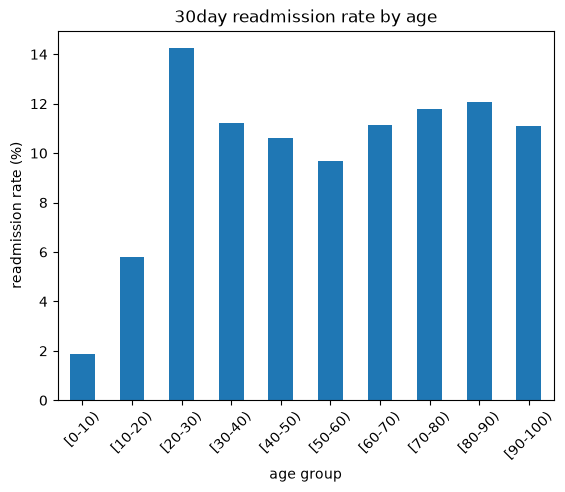

In [19]:
age_readmission.plot(kind='bar')
plt.title('30day readmission rate by age')
plt.xlabel('age group')
plt.ylabel('readmission rate (%)')
plt.xticks(rotation=45)
plt.show()

## exploring time spent in the hospital

In [20]:
df['time_in_hospital'].describe()

count    101766.000000
mean          4.395987
std           2.985108
min           1.000000
25%           2.000000
50%           4.000000
75%           6.000000
max          14.000000
Name: time_in_hospital, dtype: float64

In [21]:
#comparing hospital stay with readmission

stay_readmission=df.groupby('time_in_hospital')['readmitted_30'].mean()
stay_readmission = stay_readmission*100 #we are converting to percent
stay_readmission

time_in_hospital
1      8.178491
2      9.939619
3     10.666817
4     11.806952
5     12.030905
6     12.587876
7     12.834955
8     14.233660
9     13.724184
10    14.346712
11    10.512129
12    13.328729
13    12.314050
14    12.955854
Name: readmitted_30, dtype: float64

In [22]:
''' looks like readmission rates generally increase with longer hospital stays but the relationship 
is not perfectly consistent'''

' looks like readmission rates generally increase with longer hospital stays but the relationship \nis not perfectly consistent'

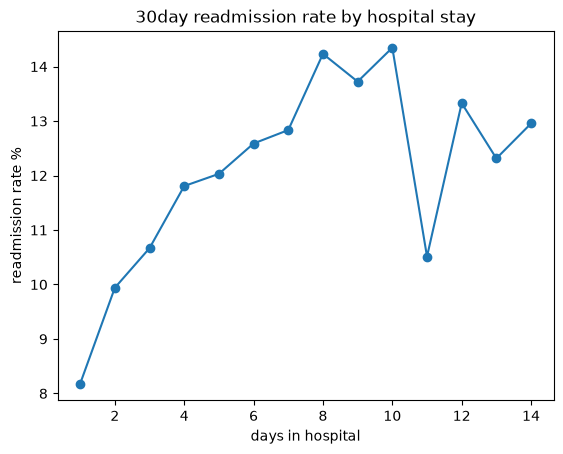

In [23]:
stay_readmission.plot(kind='line',marker='o')
plt.title('30day readmission rate by hospital stay')
plt.xlabel('days in hospital')
plt.ylabel('readmission rate %')
plt.show()

In [24]:
## exploring previous hospital visits

In [25]:
df[['number_inpatient','number_emergency', 'number_outpatient']].describe()

,number_inpatient,number_emergency,number_outpatient
count,101766.000000,101766.000000,101766.000000
mean,0.635566,0.197836,0.369357
std,1.262863,0.930472,1.267265
min,0.000000,0.000000,0.000000
25%,0.000000,0.000000,0.000000
50%,0.000000,0.000000,0.000000
75%,1.000000,0.000000,0.000000
max,21.000000,76.000000,42.000000


In [26]:
''' All three columns have a median of 0. This means at least half of the encounters have no recorded previous visits in each category.
The average number of previous inpatient visits is 0.64, compared with 0.20 emergency visits and 0.37 outpatient visits.
Patients with frequent hospital visits may have more complicated medical conditions.
'''

' All three columns have a median of 0. This means at least half of the encounters have no recorded previous visits in each category.\nThe average number of previous inpatient visits is 0.64, compared with 0.20 emergency visits and 0.37 outpatient visits.\nPatients with frequent hospital visits may have more complicated medical conditions.\n'

In [27]:
## checking readmission rate by previous inpatient visits

In [28]:
inpatient_readmission = df.groupby('number_inpatient')['readmitted_30'].mean()
inpatient_readmission = inpatient_readmission*100 #converting to percent
inpatient_readmission

number_inpatient
0       8.437084
1      12.924543
2      17.433254
3      20.287306
4      23.612824
5      31.403941
6      34.583333
7      35.447761
8      44.370861
9      42.342342
10     42.622951
11     67.346939
12     50.000000
13     50.000000
14     40.000000
15    100.000000
16     33.333333
17    100.000000
18      0.000000
19     50.000000
21    100.000000
Name: readmitted_30, dtype: float64

In [29]:
'''The readmission rate generally increases with the number of previous inpatient visits. It rises from 8.44% for no previous visits to 31.40% for five visits. This suggests that previous inpatient visits could be useful for predicting readmission. However, some higher visit counts show unusual percentages, possibly because they have very few records.'''

'The readmission rate generally increases with the number of previous inpatient visits. It rises from 8.44% for no previous visits to 31.40% for five visits. This suggests that previous inpatient visits could be useful for predicting readmission. However, some higher visit counts show unusual percentages, possibly because they have very few records.'

In [30]:
#checking the number of encounters
inpatient_count = df['number_inpatient'].value_counts()
inpatient_count = inpatient_count.sort_index()
print(inpatient_count)

number_inpatient
0     67630
1     19521
2      7566
3      3411
4      1622
5       812
6       480
7       268
8       151
9       111
10       61
11       49
12       34
13       20
14       10
15        9
16        6
17        1
18        1
19        2
21        1
Name: count, dtype: int64


In [31]:
'''Most encounters had no previous inpatient visits (67,630). As the number of previous visits increases, the number of encounters decreases. For example, only 9 encounters had 15 previous visits, and just 1 had 17 visits. This explains why some groups showed 100% readmission rates. Those percentages are based on very few records and may not be reliable.'''

'Most encounters had no previous inpatient visits (67,630). As the number of previous visits increases, the number of encounters decreases. For example, only 9 encounters had 15 previous visits, and just 1 had 17 visits. This explains why some groups showed 100% readmission rates. Those percentages are based on very few records and may not be reliable.'

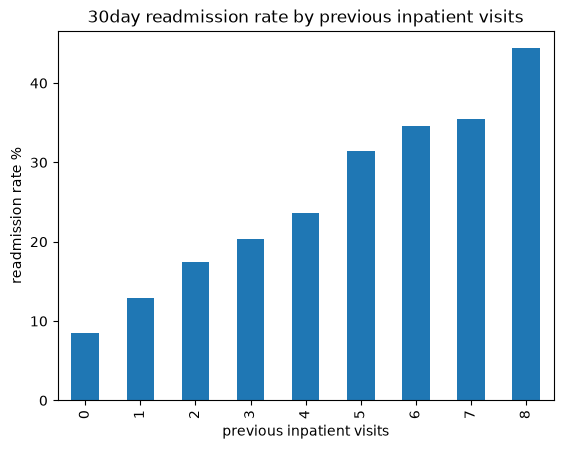

In [32]:
inpatient_graph = inpatient_readmission.loc[0:8]
inpatient_graph.plot(kind='bar')
plt.title('30day readmission rate by previous inpatient visits')
plt.xlabel('previous inpatient visits')
plt.ylabel('readmission rate %')
plt.show()

In [33]:
'''The readmission rate increases as the number of previous inpatient visits increases. It rises from 8.44% for patients with no previous inpatient visits to 44.37% for those with eight visits. This suggests that previous inpatient visits could be an important feature for predicting hospital readmission.'''

'The readmission rate increases as the number of previous inpatient visits increases. It rises from 8.44% for patients with no previous inpatient visits to 44.37% for those with eight visits. This suggests that previous inpatient visits could be an important feature for predicting hospital readmission.'

In [34]:
#exploring previous emergency visits
emergency_readmission = df.groupby('number_emergency')['readmitted_30'].mean()
emergency_readmission = emergency_readmission*100
print(emergency_readmission)

number_emergency
0      10.474315
1      14.354566
2      18.266405
3      20.275862
4      30.748663
5      24.479167
6      23.404255
7      26.027397
8      32.000000
9      36.363636
10     35.294118
11     21.739130
12     20.000000
13     33.333333
14      0.000000
15     33.333333
16     40.000000
18     20.000000
19     50.000000
20     50.000000
21     50.000000
22     50.000000
24      0.000000
25      0.000000
28    100.000000
29      0.000000
37      0.000000
42      0.000000
46      0.000000
54      0.000000
63      0.000000
64    100.000000
76      0.000000
Name: readmitted_30, dtype: float64


In [35]:
'''The readmission rate generally increases with previous emergency visits. It rises from 10.47% for no emergency visits to 30.75% for four visits. However, the rates fluctuate for higher visit counts, possibly because there are fewer records in those groups.'''

'The readmission rate generally increases with previous emergency visits. It rises from 10.47% for no emergency visits to 30.75% for four visits. However, the rates fluctuate for higher visit counts, possibly because there are fewer records in those groups.'

In [36]:
emergency_count = df['number_emergency'].value_counts()
emergency_count = emergency_count.sort_index()
emergency_count

number_emergency
0     90383
1      7677
2      2042
3       725
4       374
5       192
6        94
7        73
8        50
9        33
10       34
11       23
12       10
13       12
14        3
15        3
16        5
18        5
19        4
20        4
21        2
22        6
24        1
25        2
28        1
29        1
37        1
42        1
46        1
54        1
63        1
64        1
76        1
Name: count, dtype: int64

In [37]:
'''Most encounters had no previous emergency visits. The number of encounters decreases as emergency visits increase. Some higher visit counts have very few records, so their readmission percentages may not be reliable.'''

'Most encounters had no previous emergency visits. The number of encounters decreases as emergency visits increase. Some higher visit counts have very few records, so their readmission percentages may not be reliable.'

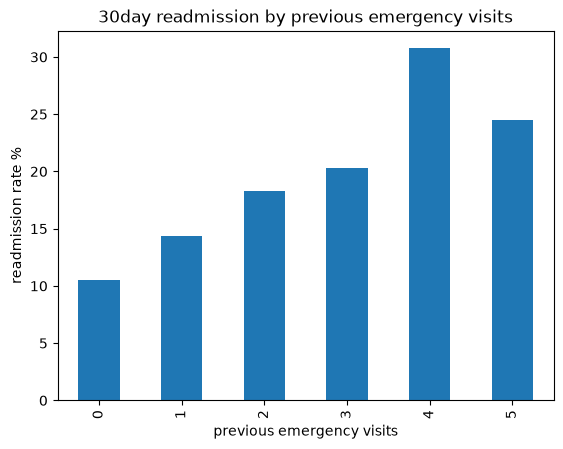

In [38]:
emergency_graph = emergency_readmission.loc[0:5]
emergency_graph.plot(kind='bar')
plt.title('30day readmission by previous emergency visits')
plt.xlabel('previous emergency visits')
plt.ylabel('readmission rate %')
plt.show()

In [39]:
#exploring previous outpatient visits

outpatient_readmission = df.groupby('number_outpatient')['readmitted_30'].mean()

outpatient_readmission =outpatient_readmission* 100
outpatient_readmission


number_outpatient
0      10.674256
1      13.923014
2      13.745131
3      12.291871
4      15.104641
5      11.819887
6      13.201320
7      15.483871
8       5.102041
9      15.662651
10      8.771930
11     14.285714
12     20.000000
13     19.354839
14     17.857143
15     10.000000
16      0.000000
17     12.500000
18      0.000000
19     33.333333
20      0.000000
21      0.000000
22     20.000000
23     50.000000
24      0.000000
25      0.000000
26      0.000000
27      0.000000
28      0.000000
29      0.000000
33      0.000000
34      0.000000
35      0.000000
36      0.000000
37      0.000000
38      0.000000
39      0.000000
40    100.000000
42      0.000000
Name: readmitted_30, dtype: float64

In [40]:
'''The readmission rate changes across different numbers of outpatient visits, but there is no clear increasing pattern. This suggests that outpatient visits may have a different relationship with readmission compared to inpatient and emergency visits.'''

'The readmission rate changes across different numbers of outpatient visits, but there is no clear increasing pattern. This suggests that outpatient visits may have a different relationship with readmission compared to inpatient and emergency visits.'

In [41]:
outpatient_count = df['number_outpatient'].value_counts()
outpatient_count = outpatient_count.sort_index()

outpatient_count


number_outpatient
0     85027
1      8547
2      3594
3      2042
4      1099
5       533
6       303
7       155
8        98
9        83
10       57
11       42
12       30
13       31
14       28
15       20
16       15
17        8
18        5
19        3
20        7
21        7
22        5
23        2
24        3
25        2
26        2
27        3
28        1
29        2
33        2
34        1
35        2
36        2
37        1
38        1
39        1
40        1
42        1
Name: count, dtype: int64

In [42]:
'''Most encounters had no previous outpatient visits. The number of encounters decreases as previous outpatient visits increase. Some higher visit counts have very few records, which may explain the unusual readmission percentages.'''

'Most encounters had no previous outpatient visits. The number of encounters decreases as previous outpatient visits increase. Some higher visit counts have very few records, which may explain the unusual readmission percentages.'

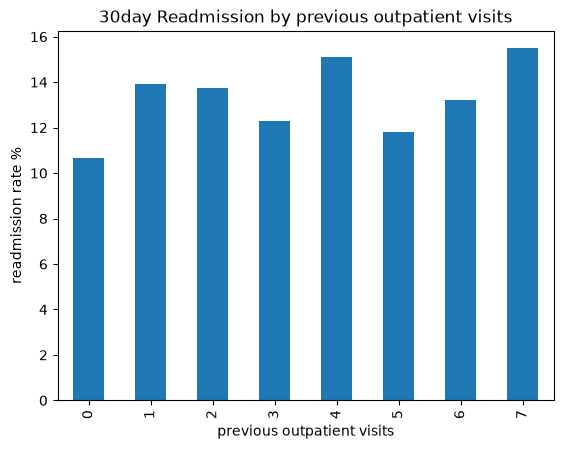

In [43]:
outpatient_graph = outpatient_readmission.loc[0:7]
outpatient_graph.plot(kind='bar' )

plt.title('30day Readmission by previous outpatient visits')
plt.xlabel('previous outpatient visits')
plt.ylabel('readmission rate %')
plt.show()


In [44]:
'''The readmission rate varies with the number of previous outpatient visits, but there is no clear increasing pattern. This suggests that outpatient visits may have a weaker relationship with 30-day readmission than inpatient visits.'''

'The readmission rate varies with the number of previous outpatient visits, but there is no clear increasing pattern. This suggests that outpatient visits may have a weaker relationship with 30-day readmission than inpatient visits.'

In [45]:
df.columns.tolist()

['encounter_id',
 'patient_nbr',
 'race',
 'gender',
 'age',
 'weight',
 'admission_type_id',
 'discharge_disposition_id',
 'admission_source_id',
 'time_in_hospital',
 'payer_code',
 'medical_specialty',
 'num_lab_procedures',
 'num_procedures',
 'num_medications',
 'number_outpatient',
 'number_emergency',
 'number_inpatient',
 'diag_1',
 'diag_2',
 'diag_3',
 'number_diagnoses',
 'max_glu_serum',
 'A1Cresult',
 'metformin',
 'repaglinide',
 'nateglinide',
 'chlorpropamide',
 'glimepiride',
 'acetohexamide',
 'glipizide',
 'glyburide',
 'tolbutamide',
 'pioglitazone',
 'rosiglitazone',
 'acarbose',
 'miglitol',
 'troglitazone',
 'tolazamide',
 'examide',
 'citoglipton',
 'insulin',
 'glyburide-metformin',
 'glipizide-metformin',
 'glimepiride-pioglitazone',
 'metformin-rosiglitazone',
 'metformin-pioglitazone',
 'change',
 'diabetesMed',
 'readmitted',
 'readmitted_30']

In [46]:
patient_visits = df.groupby('patient_nbr').size()
multiple_visits = (patient_visits > 1).sum()

print("Total unique patients:", df['patient_nbr'].nunique())
print("Patients with multiple encounters:", multiple_visits)

Total unique patients: 71518
Patients with multiple encounters: 16773


Gender Consistency Across Hospital Encounters
Since 16,773 patients have multiple hospital encounters, I want to check whether their recorded gender remains consistent across visits. This will help me understand whether gender information changes within the dataset.

In [48]:
gender_changes = df.groupby('patient_nbr')['gender'].nunique()
inconsistent_gender = (gender_changes > 1).sum()
print("Patients with different recorded gender values:", inconsistent_gender)

Patients with different recorded gender values: 3


Age Consistency Across Hospital Encounters
I will now examine whether patients with multiple hospital encounters have different recorded age groups. Since age is represented in ranges, such as [40–50) and [50–60), some patients may move into another age group between hospital visits.

In [49]:
age_changes = df.groupby('patient_nbr')['age'].nunique()
inconsistent_age = (age_changes > 1).sum()
print("Patients with different recorded age groups:", inconsistent_age)

Patients with different recorded age groups: 1574


Race Consistency Across Hospital Encounters
I will examine whether patients with multiple hospital encounters have consistent race information across their visits. This will help identify possible differences in demographic records.

In [50]:
race_changes = df.groupby('patient_nbr')['race'].nunique()
inconsistent_race = (race_changes > 1).sum()
print("Patients with different recorded race values:", inconsistent_race)

Patients with different recorded race values: 249


Comparison of Demographic Changes Across Hospital Encounters
I will compare the number of patients with different recorded gender, age, and race values across their hospital encounters. This visualization will help identify which demographic characteristics show the most variation.

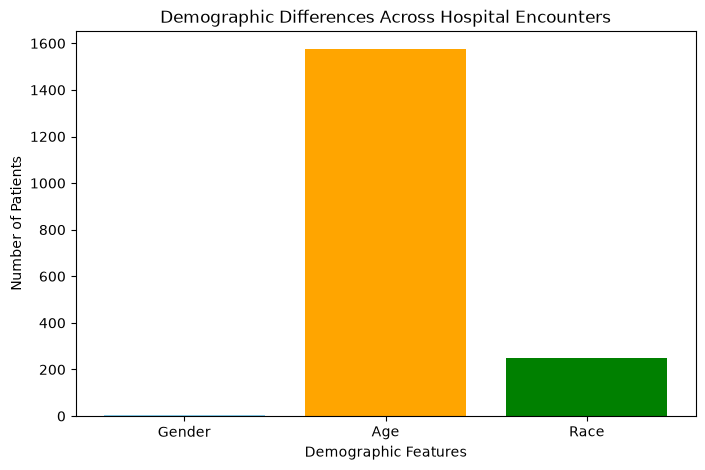

In [51]:
demographics = ['Gender', 'Age', 'Race']
changes = [inconsistent_gender, inconsistent_age, inconsistent_race]
plt.figure(figsize=(8, 5))
plt.bar(demographics, changes, color=['skyblue', 'orange', 'green'])
plt.title('Demographic Differences Across Hospital Encounters')
plt.xlabel('Demographic Features')
plt.ylabel('Number of Patients')
plt.show()

In [55]:
df['race'] = df['race'].replace('?', np.nan)
race_changes = df.groupby('patient_nbr')['race'].nunique()
inconsistent_race = (race_changes > 1).sum()
print("Patients with different recorded race values:", inconsistent_race)

Patients with different recorded race values: 123


Gender Distribution Across All Hospital Encounters
I will examine the distribution of male and female patients across all hospital encounters. This will help me understand the gender composition of the dataset before analyzing its relationship with hospital readmission.

In [56]:
gender_count = df['gender'].value_counts()
gender_percentage = (gender_count / len(df)) * 100
gender_summary = pd.DataFrame({
    'Number of Encounters': gender_count,
    'Percentage (%)': gender_percentage
})
print(gender_summary)

                 Number of Encounters  Percentage (%)
gender                                               
Female                          54708       53.758623
Male                            47055       46.238429
Unknown/Invalid                     3        0.002948


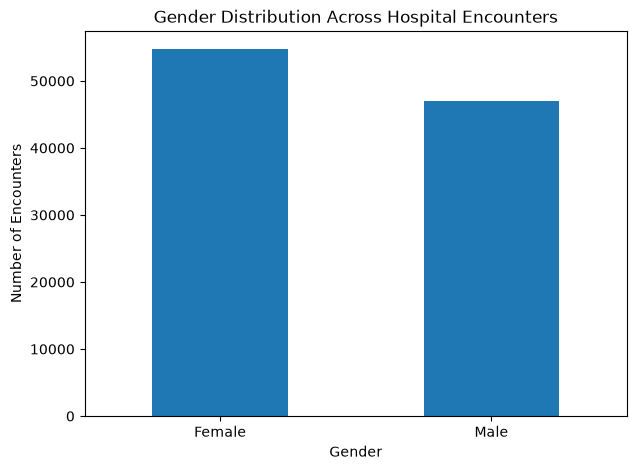

In [ ]:
gender_plot = gender_count.drop(
    index='Unknown/Invalid', errors='ignore'
)
plt.figure(figsize=(7, 5))
gender_plot.plot(kind='bar')

plt.title('Gender Distribution Across Hospital Encounters')
plt.xlabel('Gender')
plt.ylabel('Number of Encounters')
plt.xticks(rotation=0)
plt.show()

Female patients account for approximately 53.76% of hospital encounters, while male patients account for 46.24%. The gender distribution is relatively balanced, with a slightly higher representation of female patients.

In [57]:
race_count = df['race'].value_counts()
race_percentage = (race_count / df['race'].count()) * 100
race_summary = pd.DataFrame({
    'Number of Encounters': race_count,
    'Percentage (%)': race_percentage
})
print(race_summary)

                 Number of Encounters  Percentage (%)
race                                                 
Caucasian                       76099       76.486788
AfricanAmerican                 19210       19.307891
Hispanic                         2037        2.047380
Other                            1506        1.513674
Asian                             641        0.644266


From the race distribution, I noticed that Caucasian patients make up the majority of hospital encounters (76.49%), followed by African American patients (19.31%). Other racial groups have much smaller representation, showing that the dataset is not evenly distributed across races. This is something we need to keep in mind when evaluating our prediction models.

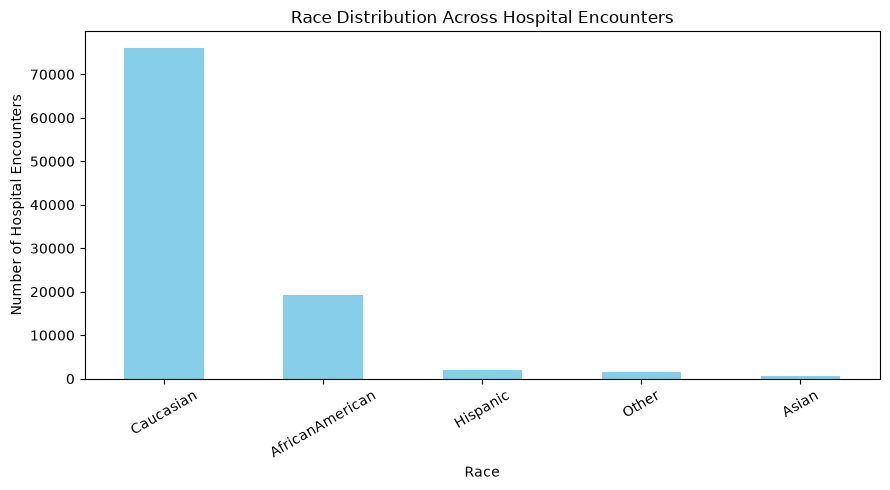

In [58]:
plt.figure(figsize=(9, 5))
race_count.plot(kind='bar', color='skyblue')
plt.title('Race Distribution Across Hospital Encounters')
plt.xlabel('Race')
plt.ylabel('Number of Hospital Encounters')
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

30-Day Readmission Rate by Gender
I want to examine whether the 30-day hospital readmission rate differs between male and female patients. This will help me understand whether gender might be useful for predicting hospital readmission.

In [59]:
gender_readmission = df.groupby('gender')['readmitted_30'].mean() * 100
print(gender_readmission)

gender
Female             11.245156
Male               11.061524
Unknown/Invalid     0.000000
Name: readmitted_30, dtype: float64


From the results, I noticed that female patients have a slightly higher 30-day readmission rate (11.25%) than male patients (11.06%). However, the difference is very small, suggesting that gender alone may not be a strong factor in predicting hospital readmission.

30-Day Readmission Rate by Race
I want to examine whether the 30-day hospital readmission rate differs among racial groups. Since the dataset has an uneven racial distribution, this analysis will help me understand whether race is associated with differences in readmission rates.

In [60]:
race_readmission = df.groupby('race')['readmitted_30'].mean() * 100
print(race_readmission.round(2))

race
AfricanAmerican    11.22
Asian              10.14
Caucasian          11.29
Hispanic           10.41
Other               9.63
Name: readmitted_30, dtype: float64


From the results, I noticed that 30-day readmission rates are quite similar across racial groups, with Caucasian patients having the highest rate (11.29%), followed closely by African American patients (11.22%). The Other category had the lowest rate (9.63%). Overall, the differences are small, but some groups have fewer records, which is important to keep in mind when comparing the results.

Distribution of Primary Diagnoses
I want to explore the most common primary diagnoses among hospital encounters. This will help me understand which medical conditions are frequently recorded and whether diagnosis information could be useful for predicting hospital readmission.

In [61]:
top_diagnoses = df['diag_1'].value_counts().head(10)
print(top_diagnoses)

diag_1
428    6862
414    6581
786    4016
410    3614
486    3508
427    2766
491    2275
715    2151
682    2042
434    2028
Name: count, dtype: int64


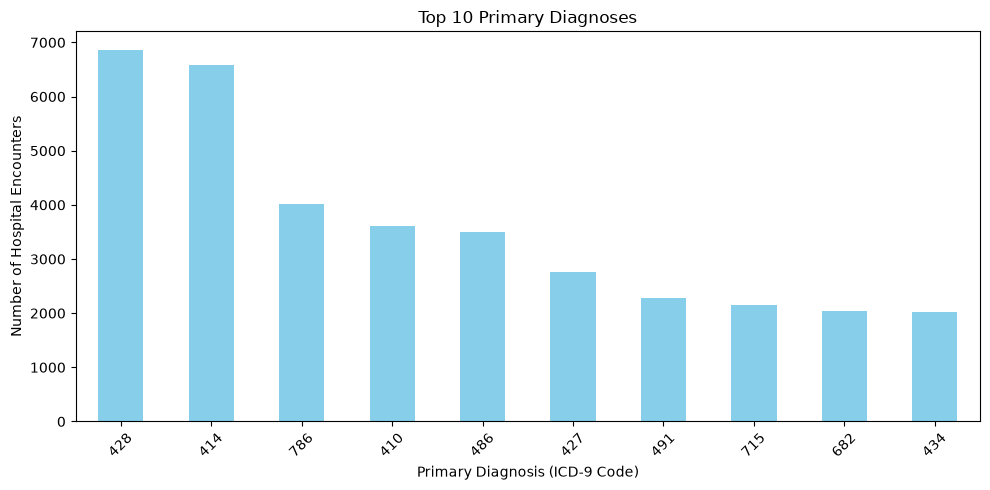

In [62]:
plt.figure(figsize=(10, 5))
top_diagnoses.plot(kind='bar', color='skyblue')
plt.title('Top 10 Primary Diagnoses')
plt.xlabel('Primary Diagnosis (ICD-9 Code)')
plt.ylabel('Number of Hospital Encounters')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

From the graph, I noticed that heart failure (ICD-9 code 428) is the most common primary diagnosis, followed by chronic ischemic heart disease (414). Other common diagnoses include respiratory symptoms, heart attacks, and pneumonia. Since several of these are heart-related conditions, they may be important factors to consider when predicting 30-day readmission.

In [ ]:
30-Day Readmission Rate by Primary Diagnosis
I want to examine the 30-day readmission rates for the 10 most common primary diagnoses. This will help me understand whether frequently recorded diagnoses also have higher readmission rates and whether diagnosis information could be useful for our prediction models

In [63]:
top_diagnosis_codes = top_diagnoses.index
diagnosis_readmission = (
    df[df['diag_1'].isin(top_diagnosis_codes)]
    .groupby('diag_1')['readmitted_30']
    .mean() * 100
)
diagnosis_readmission = diagnosis_readmission.sort_values(ascending=False)
print(diagnosis_readmission.round(2))

diag_1
434    16.22
428    14.11
491    12.62
410    10.32
715    10.00
427     9.11
414     9.04
682     8.96
486     8.95
786     7.25
Name: readmitted_30, dtype: float64


From the results, I noticed that ICD-9 code 434 had the highest 30-day readmission rate (16.22%), followed by code 428 (14.11%). Interestingly, code 428 was the most common primary diagnosis but did not have the highest readmission rate. This shows that a diagnosis being more common does not necessarily mean a higher chance of readmission, suggesting that primary diagnosis could be a useful feature for our prediction models.

In [ ]:
Distribution of A1C Test Results
I want to examine the distribution of A1C test results among hospital encounters. Since A1C is an important indicator of long-term blood glucose levels, this analysis will help me understand how A1C information is represented in the dataset.

In [64]:
a1c_count = df['A1Cresult'].value_counts()
a1c_percentage = (a1c_count / len(df)) * 100
a1c_summary = pd.DataFrame({
    'Number of Encounters': a1c_count,
    'Percentage (%)': a1c_percentage
})
print(a1c_summary.round(2))

           Number of Encounters  Percentage (%)
A1Cresult                                      
>8                         8216            8.07
Norm                       4990            4.90
>7                         3812            3.75


In [65]:
df['A1Cresult'].value_counts(dropna=False)

A1Cresult
NaN     84748
>8       8216
Norm     4990
>7       3812
Name: count, dtype: int64

From the results, I noticed that around 83% of hospital encounters have no recorded A1C results. Among the remaining encounters, 8.07% had A1C levels above 8%, 4.90% had normal results, and 3.75% were in the greater-than-7 category. Since most of the A1C information is missing, we will need to handle these missing values carefully during preprocessing.

30-Day Readmission Rate by A1C Result
I want to examine whether the 30-day hospital readmission rate differs across A1C result categories. This will help me understand whether A1C results could be useful for predicting hospital readmission.

In [66]:
a1c_readmission = (
    df.groupby('A1Cresult', dropna=False)['readmitted_30']
    .mean() * 100
)
print(a1c_readmission.round(2))

A1Cresult
>7      10.05
>8       9.87
Norm     9.66
NaN     11.42
Name: readmitted_30, dtype: float64


From the results, I noticed that encounters without recorded A1C results had the highest readmission rate (11.42%), while those with recorded results had fairly similar rates (9.66%–10.05%). Interestingly, A1C levels above 8% did not show the highest readmission rate. Since around 83% of encounters have missing A1C results, this is an important limitation to consider when building our prediction models.

Diabetes Medication and 30-Day Readmission
I want to examine whether the 30-day readmission rate differs between patients who were prescribed diabetes medication and those who were not. This will help me understand whether diabetes medication status might be useful for predicting hospital readmission

In [67]:
medication_readmission = df.groupby('diabetesMed').agg(
    encounters=('readmitted_30', 'size'),
    readmission_rate=('readmitted_30', 'mean')
)
medication_readmission['readmission_rate'] *= 100
print(medication_readmission.round(2))

             encounters  readmission_rate
diabetesMed                              
No                23403              9.60
Yes               78363             11.63


Patients prescribed diabetes medication had a slightly higher 30-day readmission rate (11.63%) than those who were not (9.60%). This suggests a possible relationship, although other factors, such as health conditions and disease severity, may also play a role.

Numerical Feature Correlation Analysis
I want to examine the relationships between numerical features in the dataset and see how they correlate with 30-day hospital readmission. This will help me identify any strong relationships between features and understand which ones might be useful for our prediction models.

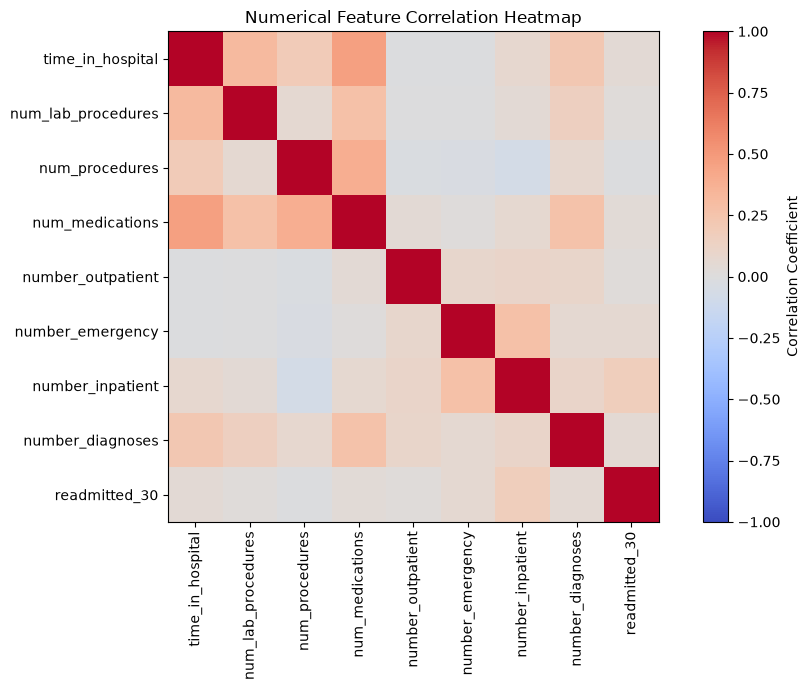

In [68]:
numeric_features = [
    'time_in_hospital',
    'num_lab_procedures',
    'num_procedures',
    'num_medications',
    'number_outpatient',
    'number_emergency',
    'number_inpatient',
    'number_diagnoses',
    'readmitted_30'
]

correlation_matrix = df[numeric_features].corr()
plt.figure(figsize=(10, 7))
plt.imshow(correlation_matrix, cmap='coolwarm', vmin=-1, vmax=1)
plt.colorbar(label='Correlation Coefficient')
plt.xticks(range(len(numeric_features)), numeric_features, rotation=90)
plt.yticks(range(len(numeric_features)), numeric_features)
plt.title('Numerical Feature Correlation Heatmap')
plt.tight_layout()
plt.show()

From the heatmap, I noticed that longer hospital stays are associated with more medications, and the number of procedures also shows a positive relationship with medications. Previous inpatient visits have the strongest correlation with 30-day readmission, although it is still relatively weak. Overall, this suggests that using multiple features together may help us better predict hospital readmission.

In [69]:
readmission_correlation = correlation_matrix['readmitted_30'].drop('readmitted_30')
print(readmission_correlation.sort_values(ascending=False).round(3))

number_inpatient      0.165
number_emergency      0.061
number_diagnoses      0.050
time_in_hospital      0.044
num_medications       0.038
num_lab_procedures    0.020
number_outpatient     0.019
num_procedures       -0.012
Name: readmitted_30, dtype: float64


From the results, I observed that previous inpatient visits have the highest correlation with 30-day readmission (0.165). However, all the correlations are relatively weak, suggesting that combining multiple features may help improve our readmission prediction models.